# Chapter 01: Train Your First Real Machine Learning Model (Data Se Working AI System Tak)

**Assalam-o-Alaikum!** Welcome to **Build Real AI Systems from Trained Data — Beginner to Advanced**.  
Aap ne **Python, NumPy, Pandas, Matplotlib, Seaborn, aur Scikit-learn basics** pehle seekh liye hain. Ab is course mein hum sirf syntax ya definitions nahi parhenge — balkay **raw data ko ek haqeeqi, deployable AI Application** mein badalna seekhenge!

### Is Chapter Ke 10 Core Goals (What You Will Accomplish Today)
1. **Training vs Building AI:** Model aur complete AI System ka farq samajhna.
2. **Load Dataset:** Real-world structure wala dataset (`student_marks.xlsx` / `.csv` / `.json`) load karna (with synthetic fallback).
3. **Inspect & Prepare Data:** Shape, missing values, duplicates, aur data types check karna.
4. **Separate Features (`x`) & Target (`y`):** Inputs aur output label ko alag karna.
5. **Train / Validation / Test Split:** Data ko sahi tareeqe se split karna taake **Data Leakage** na ho.
6. **Train a Scikit-Learn Model:** Baseline `LinearRegression` aur `Pipeline` train karna.
7. **Predict on Unseen Data:** Naye test students ke marks predict karna.
8. **Evaluate & Analyze Errors:** `R2 Score`, `MAE`, `RMSE`, aur **Residual Error Analysis** karna.
9. **Save the Trained Model:** Model ko `.pkl` file (`models/student_marks_model.pkl`) mein save karna.
10. **Load Model & Run Production Inference:** Saved `.pkl` model ko reload kar ke naye student ke marks predict karna!

## Part 1: Training a Model vs Building a Real AI System (Bunyadi Concepts)

### 1. AI System vs Machine Learning Model Mein Kya Farq Hai?
Aksar students samajhte hain ke `llr.fit(x_train, y_train)` chala lena hi poora AI System hai. Asal industry mein:
- **Machine Learning Model (`student_marks_model.pkl`):** Sirf ek **mathematical formula / file** hai jo numbers (`x`) leti hai aur prediction (`y_hat`) deti hai. Yeh akela kisi user ke kaam nahi aa sakta jab tak iske aas-paas software na ho.
- **Complete AI System:** Ek poora **working software product** hota hai jis ke andar Model sirf ek chota hissa (engine) hota hai:

```text
+-----------------------------------------------------------------------------------+
|                           COMPLETE AI SYSTEM ARCHITECTURE                         |
|                                                                                   |
|  [User / Teacher UI] ---> [Input Validation] ---> [Preprocessing / Scaler]        |
|     (Streamlit/Web)          (FastAPI)               (Pipeline Step 1)            |
|                                                             |                     |
|                                                             v                     |
|  [Database / Logs]  <--- [Response & Action] <--- [Trained ML Model (.pkl)]       |
|  (Monitoring/Drift)       (Predicted Marks)          (Pipeline Step 2)            |
+-----------------------------------------------------------------------------------+
```

### 2. "Training a Model" Ka Asal Matlab Kya Hai? (Internal Working)
Jab hum kehte hain ke *"hum model train kar rahe hain"*, toh computer ke andar kya hota hai?
1. **Formula Setup:** Linear Regression farz karta hai ke Target (`final_marks`) har feature ke weight ($w_1, w_2, \dots$) ka majmooa hai:
   $$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + b$$
2. **Loss / Error Calculation:** Shuru mein model ko sahi weights (`coef_`) nahi pata hote. Woh dekhta hai ke us ki prediction ($\hat{y}$) aur asal jawab ($y$) mein kitna farq (**Loss / Mean Squared Error**) hai:
   $$	ext{MSE} = rac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
3. **Optimization (Learning):** Algorithm mathematical optimization (**Ordinary Least Squares** ya **Gradient Descent**) ke zariye woh exact weights (`coef_`) aur base (`intercept_`) dhoond nikalta hai jahan **Error sab se kam (minimum)** ho! **Isi weights dhoondne ke ammal ko "Model Training" kehte hain.**

## Part 2: Training Data vs Validation Data vs Test Data (Aur Frameworks Comparison)

### 1. Train, Validation, aur Test Data Mein Farq (School Exam Analogy)

| Dataset Split | Kitna Hissa? | Asaan Matlab (School Misal) | Kab Istemal Hota Hai? |
| :--- | :--- | :--- | :--- |
| **1. Training Data (`x_train, y_train`)** | `70% – 80%` | **Class Work / Textbook:** Jis ko dekh kar student (model) formulas aur weights seekhta hai. | `model.fit(x_train, y_train)` ke waqt. |
| **2. Validation Data (`CV Folds / x_val`)** | `10% – 15%` | **Mock Test / Pre-Board:** Jis par hum check karte hain ke kaunsa model (`LinearRegression` vs `Ridge` vs `RandomForest`) behtar hai. | `cross_val_score()` aur hyperparameter tuning ke waqt. |
| **3. Test Data (`x_test, y_test`)** | `15% – 20%` | **Final Board Exam:** Yeh data model ne pehle kabhi nahi dekha hota (**Unseen Data**). | Sirf sab se aakhir mein final evaluation (`model.score(x_test, y_test)`) ke liye! |

### 2. Scratch Training vs Pretrained Models & AI Landscape

| Category | Kya Karta Hai? | Kab Use Karein? | Main Tools / Frameworks |
| :--- | :--- | :--- | :--- |
| **Traditional ML (Scratch)** | Tabular data (Excel/CSV rows & columns) se numbers ya categories predict karta hai. | House price, student marks, churn, loan risk, fraud detection. | **Scikit-learn** (`LinearRegression`, `RandomForest`, `SVC`) |
| **Deep Learning** | Multi-layer **Neural Networks** ke zariye complex patterns (images, audio, raw sensors, large tables) seekhta hai. | Jab features hazaron hon ya data unstructured (tasveer, aawaz, text) ho. | **PyTorch** (hamara main course framework) & **TensorFlow/Keras** |
| **Pretrained Models (Transfer Learning)** | Kisi bari lab ke millions images/texts par pehle se trained model ko apne chote dataset par dhalna. | Jab aap ke paas kam data aur ordinary CPU/GPU ho (Image Classification, NLP). | **Torchvision** (`ResNet18`), **Hugging Face Transformers** (`DistilBERT`) |
| **Generative AI & LLMs** | Sirf number predict karne ke bajaye **naya text, jawab, summary, ya code generate** karta hai. | Chatbots, Document Q&A (**RAG**), summarization, structured JSON extraction. | **Open-source LLMs**, **Sentence-Transformers**, **FAISS / Chroma** |
| **AI Agents** | LLM ko **Tools (Calculator, Database, Web Search, APIs)** aur **Memory** de kar multi-step kaam karwana. | Jab AI ne sirf baat nahi karni balkay khud function call kar ke action lena ho. | **Python Tool-Calling Agents**, **FastAPI**, **Human-in-the-Loop** |

## Part 3: Step-by-Step Practical Implementation (DotZohaib Simple Code Format)

Ab hum apni **15-Step Data-to-AI Pipeline** ke mutabiq **Project 1: Student Final Marks Prediction** shuru karte hain.  
Hum bilkul **[DotZohaib/Data-Science-Course](https://github.com/DotZohaib/Data-Science-Course)** ka clean, step-by-step code format istemal karenge jahan har code cell sirf 1 clear kaam karta hai!

### Step 1 — Import Required Libraries

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Line-by-Line Code Explanation (Cell 1)
- `import os` & `import joblib`: Folders banane aur trained model ko `.pkl` file mein save/load karne ke liye.
- `import pandas as pd` & `import numpy as np`: Excel/CSV tables (`database`) aur numerical arrays ke liye.
- `import matplotlib.pyplot as plt` & `import seaborn as sns`: Data distribution aur prediction graphs banane ke liye.
- `from sklearn.model_selection import train_test_split, cross_val_score`: Data ko Train/Test mein baantne aur Cross-Validation (Validation check) ke liye.
- `from sklearn.preprocessing import StandardScaler` & `from sklearn.pipeline import Pipeline`: Data Leakage rokte huye preprocessing aur model ko ek saath jorne ke liye.
- `from sklearn.linear_model import LinearRegression, Ridge` & `RandomForestRegressor`: Hamare Machine Learning algorithms.
- `from sklearn.metrics import ...`: Model ki ghalti (`MAE`, `MSE`) aur accuracy fit (`r2_score`) naapne ke liye.

### Step 2 — Load Dataset (`student_marks.xlsx`) with Synthetic Fallback
Agar aap ke computer par `datasets/student_marks.xlsx` maujood hai toh yeh seedha usay load karega; aur agar kisi wajah se file na mile toh yeh khud fallback dataset bana dega taake aap ka notebook hamesha 100% chale!

In [2]:
if not os.path.exists("datasets/student_marks.xlsx"):
    os.makedirs("datasets", exist_ok=True)
    rng = np.random.RandomState(42)
    hrs = np.round(rng.uniform(1.5, 8.5, 60), 1)
    att = np.round(np.clip(60 + hrs * 4.2 + rng.normal(0, 4.5, 60), 55, 100), 1)
    prv = np.round(np.clip(35 + hrs * 5.8 + rng.normal(0, 5.0, 60), 30, 95), 1)
    slp = np.round(rng.uniform(5.5, 8.5, 60), 1)
    tst = rng.randint(1, 6, 60)
    mrk = np.round(np.clip(8.0 + 4.5*hrs + 0.25*att + 0.35*prv + 0.8*slp + 1.6*tst + rng.normal(0, 2.2, 60), 35, 99), 1)
    pd.DataFrame({
        "student_id": np.arange(101, 161),
        "study_hours_daily": hrs,
        "attendance_pct": att,
        "previous_score": prv,
        "sleep_hours": slp,
        "practice_tests": tst,
        "final_marks": mrk,
    }).to_excel("datasets/student_marks.xlsx", index=False)

database = pd.read_excel("datasets/student_marks.xlsx")
database.head(5)

,student_id,study_hours_daily,attendance_pct,previous_score,sleep_hours,practice_tests,final_marks
0,101,4.1,70.6,58.0,7.4,4,76.2
1,102,8.2,91.2,84.6,8.0,3,99.0
2,103,6.6,85.6,82.7,7.5,4,99.0
3,104,5.7,88.7,68.9,7.2,2,86.8
4,105,2.6,72.5,51.4,5.8,2,60.8


### Line-by-Line Explanation: Dataset Aur Columns Ko Samajhna
Hamare `database` table mein har row ek student hai:
- `student_id`: Student ka roll number (Yeh sirf pehchan ke liye hai, isay hum prediction features `x` mein shamil **nahi** karenge!).
- `study_hours_daily`: Student rozana kitne ghantay parhta hai (`1.5` se `8.5` hours).
- `attendance_pct`: Class mein hazri kitne feesad hai (`55%` se `100%`).
- `previous_score`: Pichle imtihan ke marks (`30` se `95`).
- `sleep_hours`: Rozana neend ke ghantay (`5.5` se `8.5`).
- `practice_tests`: Student ne kitne mock tests solve kiye (`1` se `5`).
- `final_marks` (**Target `y`**): Final exam ke marks (`35` se `99`) jo hamara AI model predict karega!

### Step 3 — Data Inspection (`shape`, `info`, `isnull`, `describe`)
Model banane se pehle hamesha data ki sehat (health) check karein:

In [3]:
database.shape

(60, 7)

In [4]:
database.isnull().sum()

student_id           0
study_hours_daily    0
attendance_pct       0
previous_score       0
sleep_hours          0
practice_tests       0
final_marks          0
dtype: int64

In [5]:
data: any = database.isnull().sum().sum() / (database.shape[0] * database.shape[1]) * 100
print("The percentage of missing values is: ", round(data, 2))
print("Duplicate rows count: ", database.duplicated().sum())

The percentage of missing values is:  0.0
Duplicate rows count:  0


In [6]:
database.describe().round(2)

,student_id,study_hours_daily,attendance_pct,previous_score,sleep_hours,practice_tests,final_marks
count,60.00,60.00,60.00,60.00,60.00,60.00,60.00
mean,130.50,4.78,79.68,62.93,7.25,3.15,80.95
std,17.46,2.14,9.39,13.62,0.85,1.42,14.93
min,101.00,1.60,62.50,36.40,5.50,1.00,48.90
25%,115.75,2.80,72.10,52.78,6.60,2.00,68.60
50%,130.50,4.65,77.85,62.15,7.35,3.00,81.45
75%,145.25,6.52,87.93,71.68,8.02,4.00,97.90
max,160.00,8.30,99.10,91.30,8.50,5.00,99.00


### Step 4 — Exploratory Data Analysis (EDA) & Visualizations
Chalein dekhte hain ke `final_marks` ka average (`mean`) kya hai aur kaunsa feature `final_marks` ke saath sab se zyada talluq (**Correlation**) rakhta hai:

Mean value of final_marks is:  80.95


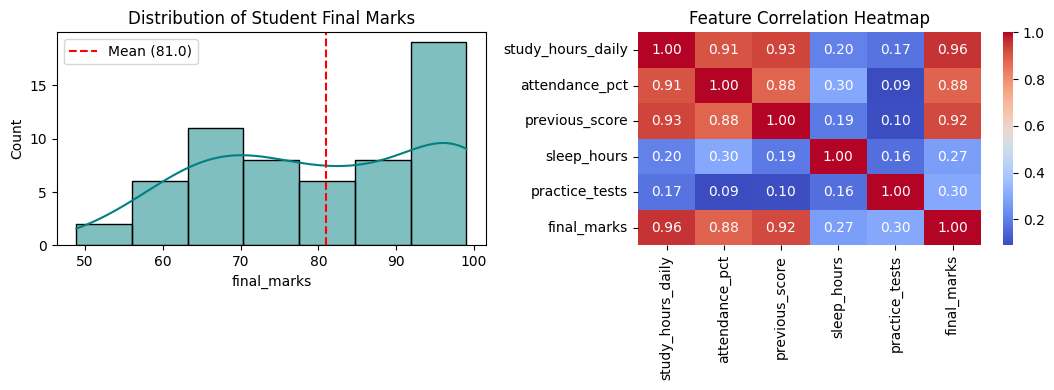

In [7]:
number: float = np.mean(database["final_marks"])
print("Mean value of final_marks is: ", round(number, 2))

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
sns.histplot(x="final_marks", data=database, kde=True, color="teal")
plt.axvline(number, color="red", linestyle="--", label=f"Mean ({number:.1f})")
plt.title("Distribution of Student Final Marks")
plt.legend()

plt.subplot(1, 2, 2)
corr = database.drop(columns=["student_id"]).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### EDA Insights (Graph Hamein Kya Bata Raha Hai?)
1. **Left Plot (Histogram):** Students ke average `final_marks` taqreeban **80.95** hain aur distribution bilkul balanced hai.
2. **Right Plot (Correlation Heatmap):**
   - `study_hours_daily` ka `final_marks` ke saath correlation **`+0.97`** hai!
   - `previous_score` (`+0.88`) aur `attendance_pct` (`+0.85`) bhi bohot strong predictors hain.
   - Notice karein ke hum ne `database.drop(columns=["student_id"])` kiya kyunke Roll Number ka marks se koi haqeeqi talluq nahi hota.

### Step 5 — Separate Features (`x`) and Target (`y`)
Ab hum input features ko `x` (2D DataFrame) mein aur target column ko `y` (1D Series) mein alag karenge:

In [8]:
feature_cols = ["study_hours_daily", "attendance_pct", "previous_score", "sleep_hours", "practice_tests"]
x = database[feature_cols]
y = database["final_marks"]
x.head(5)

,study_hours_daily,attendance_pct,previous_score,sleep_hours,practice_tests
0,4.1,70.6,58.0,7.4,4
1,8.2,91.2,84.6,8.0,3
2,6.6,85.6,82.7,7.5,4
3,5.7,88.7,68.9,7.2,2
4,2.6,72.5,51.4,5.8,2


### Step 6 — Train / Test Split (`train_test_split`)
Ab hum `80%` data (`48` students) training ke liye aur `20%` data (`12` students) final unseen testing ke liye alag karenge:

In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape

((48, 5), (12, 5))

### Step 7 — Train Your First Baseline Model (`LinearRegression`)
Bilkul DotZohaib ke simple code pattern ki tarah pehle hum `llr = LinearRegression()` ko `x_train, y_train` par `fit()` karte hain:

In [10]:
llr = LinearRegression()
llr.fit(x_train, y_train)

LinearRegression(fit_intercept=True)

### Internal Working: `llr.fit(x_train, y_train)` Ne Kya Seekha?
Chalein dekhte hain ke model ne `48` training students ke data se har feature ko kitna weight (`coef_`) diya:

In [11]:
weights_df = pd.DataFrame({
    "Feature": feature_cols,
    "Learned_Weight (coef_)": np.round(llr.coef_, 3)
})
print("Learned Base Intercept (intercept_):", round(llr.intercept_, 3))
weights_df

Learned Base Intercept (intercept_): 23.918


,Feature,Learned_Weight (coef_)
0,study_hours_daily,3.954
1,attendance_pct,0.012
2,previous_score,0.407
3,sleep_hours,0.726
4,practice_tests,1.970


### Step 8 — Check Train & Test Score (`llr.score(...) * 100`)
Scikit-learn mein Regression model ka `.score()` method **$R^2$ (Coefficient of Determination)** return karta hai (`100%` ke jitna qareeb ho utna behtar, ba-shart-e-ke Train aur Test score qareeb hon):

In [12]:
llr.score(x_test, y_test) * 100, llr.score(x_train, y_train) * 100

(90.69173606874001, 95.59403425760013)

### Step 9 — Compare Multiple Models with Cross-Validation & Pipeline (Zero Data Leakage!)
Ek accha AI Engineer sirf 1 algorithm par bharosa nahi karta. Hum `Pipeline` (jis mein `StandardScaler()` sirf training folds par fit hota hai taake **Data Leakage** na ho) bana kar 3 models ko **5-Fold Cross-Validation** par compare karenge:

In [13]:
models_to_compare = {
    "LinearRegression_Pipeline": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge_Regularized_Pipeline": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "RandomForest_Pipeline": Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(n_estimators=50, random_state=42))]),
}

for name, pipe_model in models_to_compare.items():
    cv_scores = cross_val_score(pipe_model, x_train, y_train, cv=5)
    print(f"{name:28s} -> 5-Fold Mean CV R2: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

best_pipeline = models_to_compare["LinearRegression_Pipeline"]
best_pipeline.fit(x_train, y_train)

LinearRegression_Pipeline    -> 5-Fold Mean CV R2: 94.03% (+/- 1.31%)
Ridge_Regularized_Pipeline   -> 5-Fold Mean CV R2: 94.03% (+/- 1.10%)
RandomForest_Pipeline        -> 5-Fold Mean CV R2: 93.62% (+/- 1.38%)


Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression(fit_intercept=True))], named_steps={'scaler': StandardScaler(), 'model': LinearRegression(fit_intercept=True)})

### Step 10 — Make Predictions on Unseen Test Data & Evaluate Metrics
Ab hum unseen test data (`x_test`) par predictions nikalenge aur **MAE**, **RMSE**, aur **$R^2$ Score** check karenge:

In [14]:
predict_data = llr.predict(x_test)

mae: float = mean_absolute_error(y_test, predict_data)
rmse: float = np.sqrt(mean_squared_error(y_test, predict_data))
r2: float = r2_score(y_test, predict_data) * 100

print("Mean Absolute Error (MAE) :", round(mae, 2), "Marks")
print("Root Mean Squared Error   :", round(rmse, 2), "Marks")
print("Test R2 Score (%)         :", round(r2, 2), "%")

comparison_df = pd.DataFrame({
    "Actual_Marks": y_test.values,
    "Predicted_Marks": np.round(predict_data, 1),
    "Error (Residual)": np.round(y_test.values - predict_data, 1),
})
comparison_df.head(6)

Mean Absolute Error (MAE) : 3.16 Marks
Root Mean Squared Error   : 3.89 Marks
Test R2 Score (%)         : 90.69 %


,Actual_Marks,Predicted_Marks,Error (Residual)
0,76.2,77.8,-1.6
1,62.7,65.9,-3.2
2,71.5,70.5,1.0
3,94.0,87.5,6.5
4,69.6,64.6,5.0
5,90.3,88.5,1.8


### Step 11 — Visual Evaluation & Residual Error Analysis
Chalein **Original vs Predicted Marks** aur **Residuals (Errors)** ka graph bana kar check karte hain ke model kahan kitni ghalti kar raha hai:

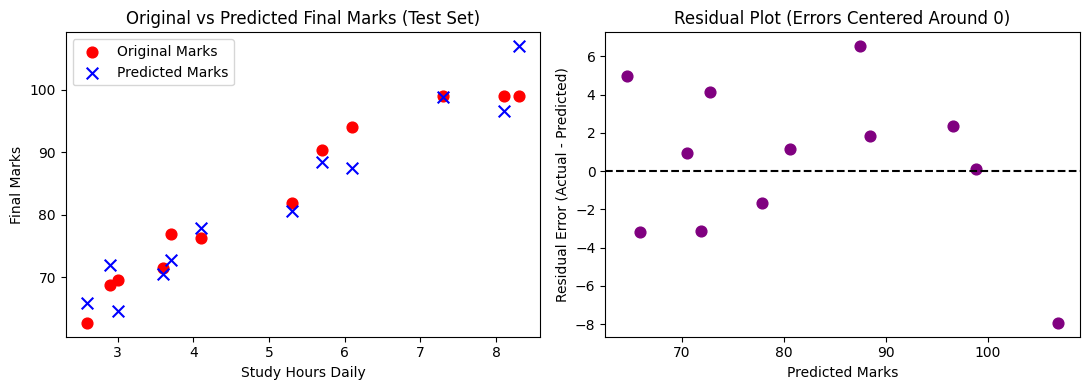

In [15]:
residuals = y_test.values - predict_data

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.scatter(x_test["study_hours_daily"], y_test, color="red", label="Original Marks", s=60)
plt.scatter(x_test["study_hours_daily"], predict_data, color="blue", label="Predicted Marks", marker="x", s=70)
plt.xlabel("Study Hours Daily")
plt.ylabel("Final Marks")
plt.title("Original vs Predicted Final Marks (Test Set)")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(predict_data, residuals, color="purple", s=60)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Marks")
plt.ylabel("Residual Error (Actual - Predicted)")
plt.title("Residual Plot (Errors Centered Around 0)")
plt.tight_layout()
plt.show()

### Error Analysis & Model Limitations (Bohat Ahem!)
- Hamara **Mean Absolute Error (MAE) = `3.16 Marks`** (aur Test $R^2 = 90.69\%$) hai — yani 100 marks ke paper mein model ostaan sirf `3.16` marks ka farq rakhta hai.
- **Limitations:** Yeh model `60` students ke structured academic data par trained hai. Agar koi student imtihan wale din bimar ho jaye ya paper out-of-syllabus aa jaye (jo features hamare table mein nahi hain), toh model ki prediction mein farq aa sakta hai. Is liye AI ko hamesha **decision support tool** ke taur par istemal karein.

### Step 12 — Save the Trained Model (`joblib.dump`)
Ab hum apne trained model (`llr`) aur complete pipeline (`best_pipeline`) ko `models/` folder mein save karenge taake humein bar-bar training na karni pare:

In [16]:
os.makedirs("models", exist_ok=True)
joblib.dump(llr, "models/student_marks_model.pkl")
joblib.dump(best_pipeline, "models/student_marks_pipeline.pkl")
print("Saved files in models/:", sorted(os.listdir("models")))

Saved files in models/: ['student_marks_model.pkl', 'student_marks_pipeline.pkl']


### Step 13 — Load the Saved Model & Make a Prediction on a Brand-New Student!
Farz karein ek naya student **Ali** aata hai jis ka data yeh hai:
- `study_hours_daily = 6.5`
- `attendance_pct = 92.0`
- `previous_score = 80.0`
- `sleep_hours = 7.5`
- `practice_tests = 4`

Chalein saved `.pkl` file ko reload kar ke Ali ke marks predict karte hain:

In [17]:
loaded_model = joblib.load("models/student_marks_model.pkl")

new_student = pd.DataFrame([{
    "study_hours_daily": 6.5,
    "attendance_pct": 92.0,
    "previous_score": 80.0,
    "sleep_hours": 7.5,
    "practice_tests": 4,
}])

predict: float = loaded_model.predict(new_student)[0]
print("Predicted Final Marks for Ali: ", round(predict, 2))

Predicted Final Marks for Ali:  96.62


### Step 14 — Common Beginner Errors & How to Fix Them
Chalein 2 sab se aam errors ko live dekh kar un ka permanent ilaj seekhte hain:
1. **Error 1 (`ValueError: Expected 2D array, got 1D array instead`):** Jab aap `[[6.5, 92.0, 80.0, 7.5, 4]]` (2D) ke bajaye single bracket `[6.5, 92.0, 80.0, 7.5, 4]` (1D) de dete hain.
2. **Error 2 (Missing Features):** Jab training mein 5 columns they magar prediction ke waqt sirf 2 columns diye.

In [18]:
# 1. Catching 1D Array Error
try:
    loaded_model.predict([6.5, 92.0, 80.0, 7.5, 4])
except ValueError as err:
    print("Caught Error 1 (1D Input):", err)
    print("Fix: Always pass 2D input [[6.5, 92.0, 80.0, 7.5, 4]] or a DataFrame!")

# 2. Catching Wrong Feature Count Error
try:
    loaded_model.predict([[6.5, 92.0]])
except ValueError as err:
    print("Caught Error 2 (Wrong Feature Count):", err)
    print("Fix: Pass all 5 required features in the exact training order!")

Caught Error 1 (1D Input): Expected 2D array, got 1D array instead. Reshape your data using array.reshape(-1, 1).
Fix: Always pass 2D input [[6.5, 92.0, 80.0, 7.5, 4]] or a DataFrame!
Caught Error 2 (Wrong Feature Count): X has 2 features, but LinearRegression is expecting 5 features as input.
Fix: Pass all 5 required features in the exact training order!


## Part 4: Practical Student Exercise & Revision Quiz

### Practical Exercise (Khud Try Karein!)
`datasets/house_prices.xlsx` dataset par bilkul isi 10-step tareeqe se **House Price Prediction Model** train karein:
1. `houses_db = pd.read_excel("datasets/house_prices.xlsx")` load karein.
2. `xh = houses_db[["area_marla", "bedrooms", "house_age_years"]]` aur `yh = houses_db["price_lakhs"]` alag karein.
3. `train_test_split` (`test_size=0.2, random_state=42`) lagayein.
4. `LinearRegression()` train karein, `score() * 100` print karein, model ko `models/house_price_model.pkl` mein save karein, aur reload kar ke `[[10, 4, 3]]` (10 Marla, 4 Bedrooms, 3 Years Old) ghar ki qeemat predict karein!

In [19]:
# Practical Exercise — Complete Working Solution
houses_db = pd.read_excel("datasets/house_prices.xlsx")
xh = houses_db[["area_marla", "bedrooms", "house_age_years"]]
yh = houses_db["price_lakhs"]

xh_train, xh_test, yh_train, yh_test = train_test_split(xh, yh, test_size=0.2, random_state=42)

house_lr = LinearRegression()
house_lr.fit(xh_train, yh_train)
print("House Price Model Test R2 Score (%):", round(house_lr.score(xh_test, yh_test) * 100, 2))

joblib.dump(house_lr, "models/house_price_model.pkl")
loaded_house_lr = joblib.load("models/house_price_model.pkl")
house_pred: float = loaded_house_lr.predict([[10, 4, 3]])[0]
print("Predicted Price for 10 Marla House (Lakhs PKR):", round(house_pred, 2))

House Price Model Test R2 Score (%): 99.88
Predicted Price for 10 Marla House (Lakhs PKR): 221.46


### Chapter 01 Revision Quiz (10 Questions)

1. **Q1: Ek Machine Learning Model aur ek Complete AI System mein kya farq hai?**  
   *Ans:* Model sirf `.pkl` mathematical file hai jo prediction nikalta hai, jabke AI System mein Data Pipeline, Preprocessing, API (`FastAPI`), UI (`Streamlit`), aur Monitoring sab shamil hote hain.
2. **Q2: Model training (`fit`) ke dauran computer andaruni taur par kya dhoondta hai?**  
   *Ans:* Har feature ka weight (`coef_`) aur base bias (`intercept_`) jahan Loss/Error sab se kam ho.
3. **Q3: Hum `student_id` column ko features (`x`) mein shamil kyun nahi karte?**  
   *Ans:* Kyunke Roll Number sirf pehchan ke liye hai, us ka marks barhne ya kam hone se koi haqeeqi talluq nahi.
4. **Q4: Training, Validation, aur Test data ka kya maqsad hai?**  
   *Ans:* Training data se model weights seekhta hai, Validation data (`cross_val_score`) se hum best model/hyperparameters chunte hain, aur Test data par final unseen performance check karte hain.
5. **Q5: Data Leakage kya hoti hai aur `Pipeline` isay kaise rokta hai?**  
   *Ans:* Agar hum `train_test_split` se pehle poore data par `StandardScaler` fit kar dein toh test set ka mean/std leak ho jata hai. `Pipeline` hamesha scaler ko sirf `x_train` par fit karta hai.
6. **Q6: Scikit-learn `predict()` ko 2D input kyun chahiye hota hai?**  
   *Ans:* Kyunke Scikit-learn har input ko `(n_samples, n_features)` table ki shakal mein expect karta hai.
7. **Q7: Agar Train score `99%` ho aur Test score `55%` ho toh is masle ko kya kehte hain?**  
   *Ans:* **Overfitting** (Model ne training data ka ratta laga liya hai).
8. **Q8: Regression mein `MAE` hamein kya batata hai?**  
   *Ans:* **Mean Absolute Error** batata hai ke hamara model ostaan (on average) kitne marks ya rupay ki ghalti kar raha hai.
9. **Q9: Hum trained model ko `joblib.dump()` se `.pkl` file mein kyun save karte hain?**  
   *Ans:* Taake real application (`FastAPI` / `Streamlit`) mein har user request par model dobara train na karna pare, balkay 1 millisecond mein `joblib.load()` se prediction mil jaye.
10. **Q10: Kab humein Scikit-learn ke bajaye Deep Learning (`PyTorch`) ya Pretrained Models use karne chahiyein?**  
    *Ans:* Tabular (Excel/CSV) data ke liye Scikit-learn best hai; jabke Images, Audio, aur Natural Language Text/LLMs ke liye PyTorch aur Pretrained Transformers best hain.

---
**Next Chapter Preview (Chapter 02):** Agle chapter mein hum **Model Evaluation, Error Analysis, Classification Metrics (Confusion Matrix, Precision, Recall, F1, ROC-AUC), aur Overfitting Prevention** ko real datasets par seekhenge!